In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pywt
from matplotlib.gridspec import GridSpec

## 1. Load and Preprocess the Image

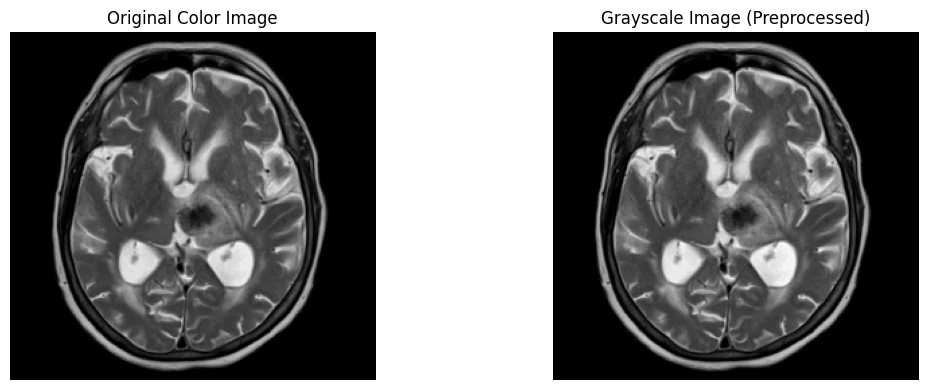

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(259, 272), dtype=float32)

In [2]:
img_path = 'img.jpg'
original_img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(original_img, cv2.COLOR_BGR2GRAY)

img_normalized = img_gray.astype(np.float32) / 255.0

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(img_rgb)
axes[0].set_title('Original Color Image')
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title('Grayscale Image (Preprocessed)')
axes[1].axis('off')

plt.tight_layout()
plt.show()

img_normalized

## 2. Single-Level 2D DWT Decomposition (Haar Wavelet)

In [3]:
wavelet = 'haar'

coeffs = pywt.dwt2(img_normalized, wavelet)
LL, (LH, HL, HH) = coeffs

coeffs

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]], shape=(130, 136), dtype=float32),
 (array([[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]], shape=(130, 136), dtype=float32),
  array([[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]], shape=(130, 136), dtype=float32),
  array([[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
      

## 3-5. Display Single-Level DWT Sub-bands and Their Characteristics

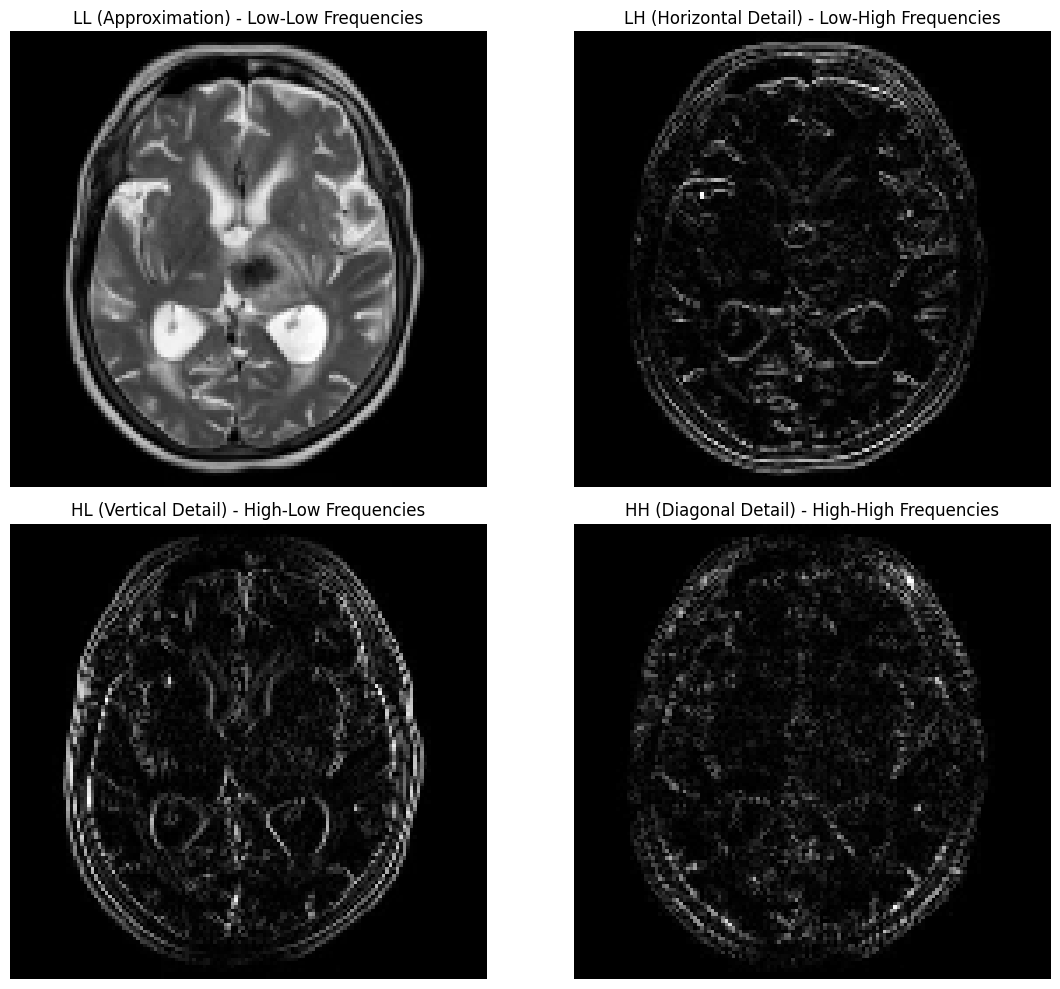

{'LL': {'shape': (130, 136),
  'min': np.float32(0.0),
  'max': np.float32(1.8647059),
  'mean': np.float32(0.40727052),
  'std': np.float32(0.45886907),
  'description': 'Approximation coefficients - Contains overall structure and low-frequency information (brightness variations)'},
 'LH': {'shape': (130, 136),
  'min': np.float32(-0.4137255),
  'max': np.float32(0.44117644),
  'mean': np.float32(0.00017955384),
  'std': np.float32(0.051861763),
  'description': 'Horizontal detail coefficients - Captures vertical edges and horizontal transitions'},
 'HL': {'shape': (130, 136),
  'min': np.float32(-0.4470589),
  'max': np.float32(0.4215686),
  'mean': np.float32(-0.00010169914),
  'std': np.float32(0.062154643),
  'description': 'Vertical detail coefficients - Captures horizontal edges and vertical transitions'},
 'HH': {'shape': (130, 136),
  'min': np.float32(-0.19803923),
  'max': np.float32(0.2019608),
  'mean': np.float32(-2.428805e-05),
  'std': np.float32(0.019559752),
  'descri

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(LL, cmap='gray')
axes[0, 0].set_title('LL (Approximation) - Low-Low Frequencies')
axes[0, 0].axis('off')

axes[0, 1].imshow(np.abs(LH), cmap='gray')
axes[0, 1].set_title('LH (Horizontal Detail) - Low-High Frequencies')
axes[0, 1].axis('off')

axes[1, 0].imshow(np.abs(HL), cmap='gray')
axes[1, 0].set_title('HL (Vertical Detail) - High-Low Frequencies')
axes[1, 0].axis('off')

axes[1, 1].imshow(np.abs(HH), cmap='gray')
axes[1, 1].set_title('HH (Diagonal Detail) - High-High Frequencies')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

subband_info = {
    'LL': {
        'shape': LL.shape,
        'min': LL.min(),
        'max': LL.max(),
        'mean': LL.mean(),
        'std': LL.std(),
        'description': 'Approximation coefficients - Contains overall structure and low-frequency information (brightness variations)'
    },
    'LH': {
        'shape': LH.shape,
        'min': LH.min(),
        'max': LH.max(),
        'mean': LH.mean(),
        'std': LH.std(),
        'description': 'Horizontal detail coefficients - Captures vertical edges and horizontal transitions'
    },
    'HL': {
        'shape': HL.shape,
        'min': HL.min(),
        'max': HL.max(),
        'mean': HL.mean(),
        'std': HL.std(),
        'description': 'Vertical detail coefficients - Captures horizontal edges and vertical transitions'
    },
    'HH': {
        'shape': HH.shape,
        'min': HH.min(),
        'max': HH.max(),
        'mean': HH.mean(),
        'std': HH.std(),
        'description': 'Diagonal detail coefficients - Captures diagonal patterns and fine-grain details'
    }
}

subband_info

## 7. Multi-Level Wavelet Decomposition (3 Levels)

In [5]:
coeffs_L1 = pywt.dwt2(img_normalized, wavelet)
LL1, (LH1, HL1, HH1) = coeffs_L1

coeffs_L2 = pywt.dwt2(LL1, wavelet)
LL2, (LH2, HL2, HH2) = coeffs_L2

coeffs_L3 = pywt.dwt2(LL2, wavelet)
LL3, (LH3, HL3, HH3) = coeffs_L3

multi_level_shapes = {
    'Level 1': {
        'LL1': LL1.shape, 'LH1': LH1.shape, 'HL1': HL1.shape, 'HH1': HH1.shape
    },
    'Level 2': {
        'LL2': LL2.shape, 'LH2': LH2.shape, 'HL2': HL2.shape, 'HH2': HH2.shape
    },
    'Level 3': {
        'LL3': LL3.shape, 'LH3': LH3.shape, 'HL3': HL3.shape, 'HH3': HH3.shape
    }
}

multi_level_shapes

{'Level 1': {'LL1': (130, 136),
  'LH1': (130, 136),
  'HL1': (130, 136),
  'HH1': (130, 136)},
 'Level 2': {'LL2': (65, 68),
  'LH2': (65, 68),
  'HL2': (65, 68),
  'HH2': (65, 68)},
 'Level 3': {'LL3': (33, 34),
  'LH3': (33, 34),
  'HL3': (33, 34),
  'HH3': (33, 34)}}

## 8. Display All Multi-Level Components

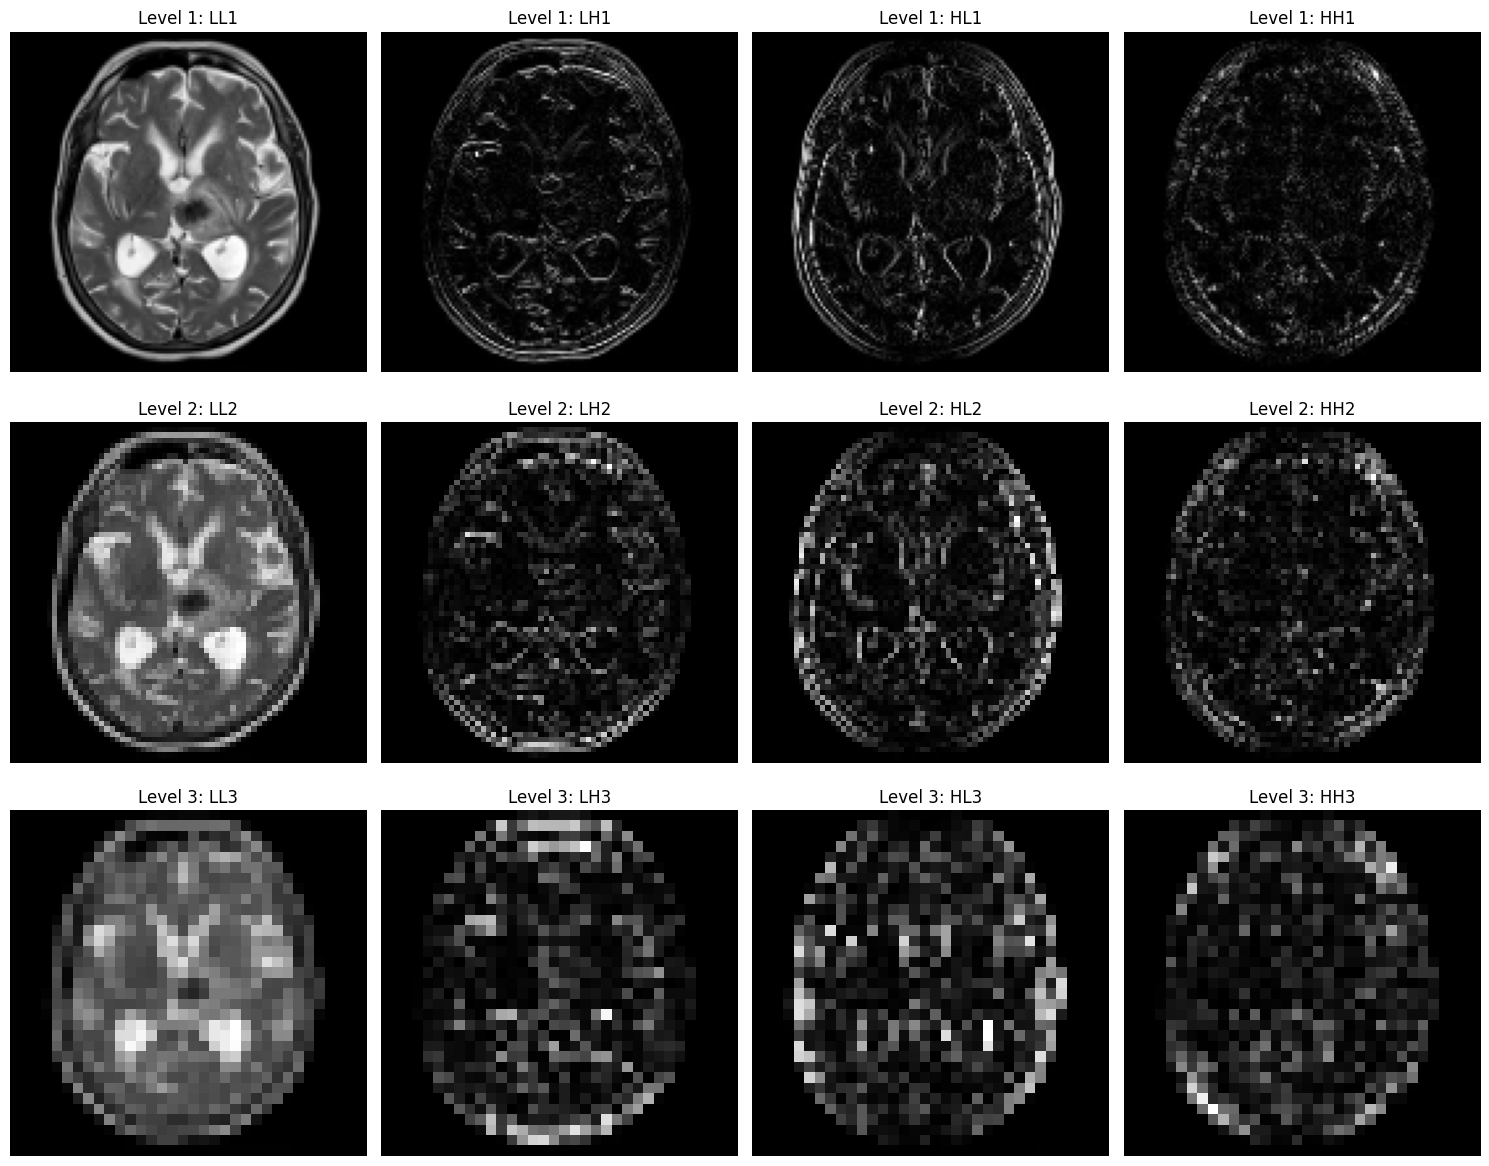

In [6]:
fig = plt.figure(figsize=(15, 12))
gs = GridSpec(3, 4, figure=fig)

ax1 = fig.add_subplot(gs[0, 0])
ax1.imshow(LL1, cmap='gray')
ax1.set_title('Level 1: LL1')
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 1])
ax2.imshow(np.abs(LH1), cmap='gray')
ax2.set_title('Level 1: LH1')
ax2.axis('off')

ax3 = fig.add_subplot(gs[0, 2])
ax3.imshow(np.abs(HL1), cmap='gray')
ax3.set_title('Level 1: HL1')
ax3.axis('off')

ax4 = fig.add_subplot(gs[0, 3])
ax4.imshow(np.abs(HH1), cmap='gray')
ax4.set_title('Level 1: HH1')
ax4.axis('off')

ax5 = fig.add_subplot(gs[1, 0])
ax5.imshow(LL2, cmap='gray')
ax5.set_title('Level 2: LL2')
ax5.axis('off')

ax6 = fig.add_subplot(gs[1, 1])
ax6.imshow(np.abs(LH2), cmap='gray')
ax6.set_title('Level 2: LH2')
ax6.axis('off')

ax7 = fig.add_subplot(gs[1, 2])
ax7.imshow(np.abs(HL2), cmap='gray')
ax7.set_title('Level 2: HL2')
ax7.axis('off')

ax8 = fig.add_subplot(gs[1, 3])
ax8.imshow(np.abs(HH2), cmap='gray')
ax8.set_title('Level 2: HH2')
ax8.axis('off')

ax9 = fig.add_subplot(gs[2, 0])
ax9.imshow(LL3, cmap='gray')
ax9.set_title('Level 3: LL3')
ax9.axis('off')

ax10 = fig.add_subplot(gs[2, 1])
ax10.imshow(np.abs(LH3), cmap='gray')
ax10.set_title('Level 3: LH3')
ax10.axis('off')

ax11 = fig.add_subplot(gs[2, 2])
ax11.imshow(np.abs(HL3), cmap='gray')
ax11.set_title('Level 3: HL3')
ax11.axis('off')

ax12 = fig.add_subplot(gs[2, 3])
ax12.imshow(np.abs(HH3), cmap='gray')
ax12.set_title('Level 3: HH3')
ax12.axis('off')

plt.tight_layout()
plt.show()

## 10. Information Content Change Across Decomposition Levels

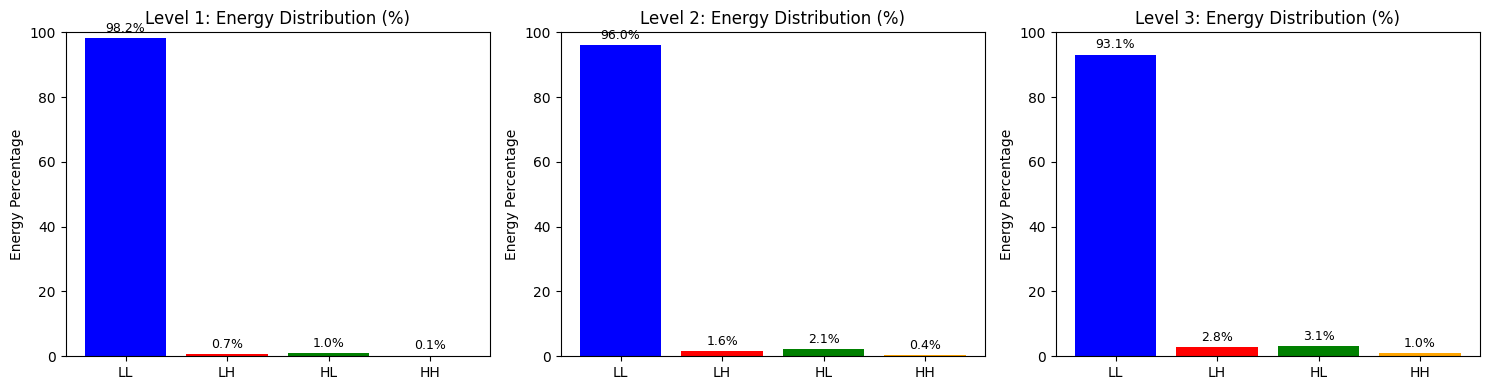

{'Level 1': {'LL': '98.19%', 'LH': '0.70%', 'HL': '1.01%', 'HH': '0.10%'},
 'Level 2': {'LL': '95.97%', 'LH': '1.55%', 'HL': '2.10%', 'HH': '0.38%'},
 'Level 3': {'LL': '93.13%', 'LH': '2.84%', 'HL': '3.06%', 'HH': '0.98%'}}

In [7]:
energy_analysis = {}

level1_ll_energy = np.sum(LL1 ** 2)
level1_lh_energy = np.sum(LH1 ** 2)
level1_hl_energy = np.sum(HL1 ** 2)
level1_hh_energy = np.sum(HH1 ** 2)
level1_total = level1_ll_energy + level1_lh_energy + level1_hl_energy + level1_hh_energy

level2_ll_energy = np.sum(LL2 ** 2)
level2_lh_energy = np.sum(LH2 ** 2)
level2_hl_energy = np.sum(HL2 ** 2)
level2_hh_energy = np.sum(HH2 ** 2)
level2_total = level2_ll_energy + level2_lh_energy + level2_hl_energy + level2_hh_energy

level3_ll_energy = np.sum(LL3 ** 2)
level3_lh_energy = np.sum(LH3 ** 2)
level3_hl_energy = np.sum(HL3 ** 2)
level3_hh_energy = np.sum(HH3 ** 2)
level3_total = level3_ll_energy + level3_lh_energy + level3_hl_energy + level3_hh_energy

energy_analysis = {
    'Level 1': {
        'LL': f"{level1_ll_energy / level1_total * 100:.2f}%",
        'LH': f"{level1_lh_energy / level1_total * 100:.2f}%",
        'HL': f"{level1_hl_energy / level1_total * 100:.2f}%",
        'HH': f"{level1_hh_energy / level1_total * 100:.2f}%",
    },
    'Level 2': {
        'LL': f"{level2_ll_energy / level2_total * 100:.2f}%",
        'LH': f"{level2_lh_energy / level2_total * 100:.2f}%",
        'HL': f"{level2_hl_energy / level2_total * 100:.2f}%",
        'HH': f"{level2_hh_energy / level2_total * 100:.2f}%",
    },
    'Level 3': {
        'LL': f"{level3_ll_energy / level3_total * 100:.2f}%",
        'LH': f"{level3_lh_energy / level3_total * 100:.2f}%",
        'HL': f"{level3_hl_energy / level3_total * 100:.2f}%",
        'HH': f"{level3_hh_energy / level3_total * 100:.2f}%",
    }
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

levels = ['LL', 'LH', 'HL', 'HH']
level1_pct = [level1_ll_energy / level1_total * 100, level1_lh_energy / level1_total * 100, 
              level1_hl_energy / level1_total * 100, level1_hh_energy / level1_total * 100]
level2_pct = [level2_ll_energy / level2_total * 100, level2_lh_energy / level2_total * 100,
              level2_hl_energy / level2_total * 100, level2_hh_energy / level2_total * 100]
level3_pct = [level3_ll_energy / level3_total * 100, level3_lh_energy / level3_total * 100,
              level3_hl_energy / level3_total * 100, level3_hh_energy / level3_total * 100]

axes[0].bar(levels, level1_pct, color=['blue', 'red', 'green', 'orange'])
axes[0].set_title('Level 1: Energy Distribution (%)')
axes[0].set_ylabel('Energy Percentage')
axes[0].set_ylim([0, 100])
for i, v in enumerate(level1_pct):
    axes[0].text(i, v + 2, f'{v:.1f}%', ha='center', fontsize=9)

axes[1].bar(levels, level2_pct, color=['blue', 'red', 'green', 'orange'])
axes[1].set_title('Level 2: Energy Distribution (%)')
axes[1].set_ylabel('Energy Percentage')
axes[1].set_ylim([0, 100])
for i, v in enumerate(level2_pct):
    axes[1].text(i, v + 2, f'{v:.1f}%', ha='center', fontsize=9)

axes[2].bar(levels, level3_pct, color=['blue', 'red', 'green', 'orange'])
axes[2].set_title('Level 3: Energy Distribution (%)')
axes[2].set_ylabel('Energy Percentage')
axes[2].set_ylim([0, 100])
for i, v in enumerate(level3_pct):
    axes[2].text(i, v + 2, f'{v:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

energy_analysis

## 11. Inverse Wavelet Transformation - Image Reconstruction

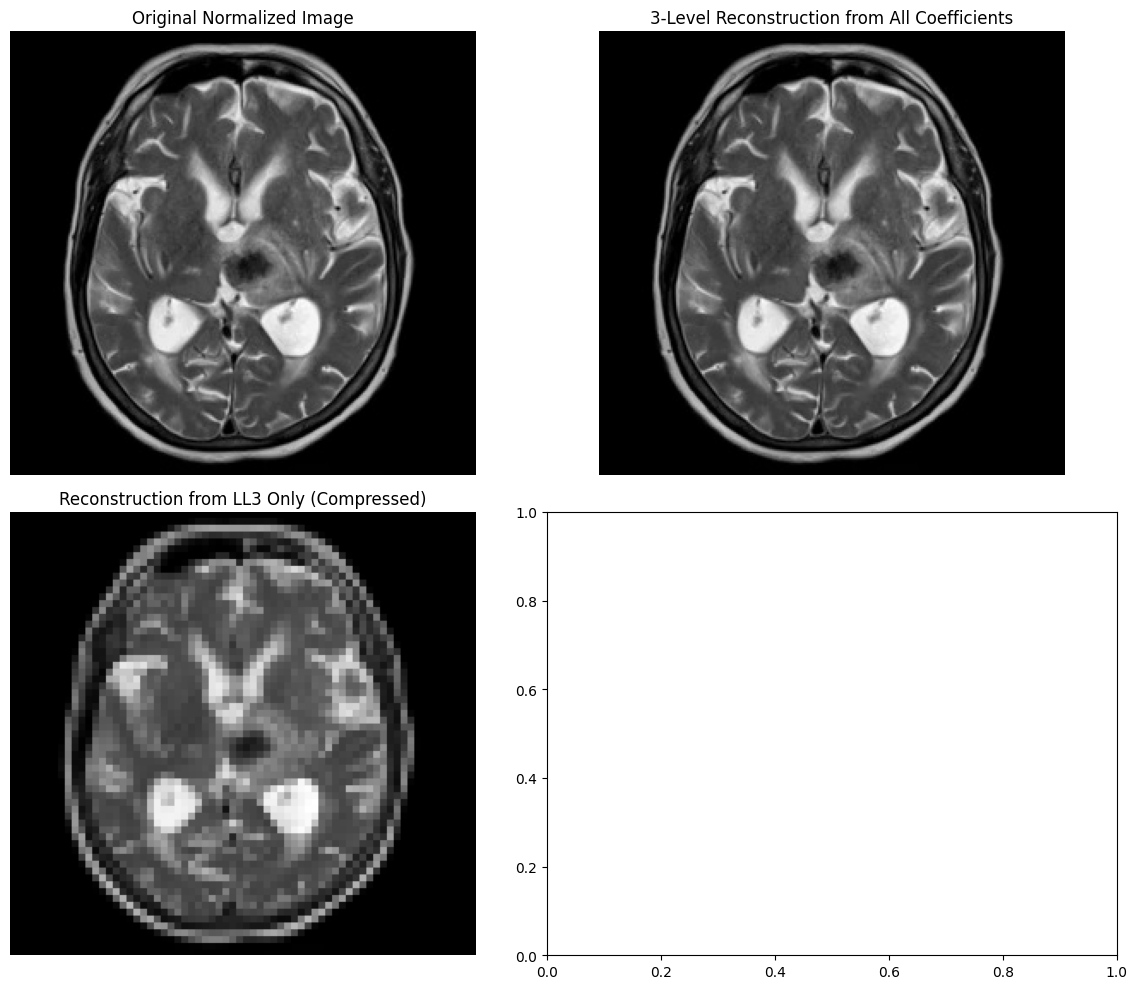

{'Full Reconstruction MSE': 5.023079442488662e-15,
 'LL3-Only MSE': 0.005551059264689684,
 'Original Shape': (259, 272),
 'Reconstructed Shape': (259, 272),
 'Reconstruction Error (Full)': 4.172325134277344e-07}

In [12]:
reconstructed_L2 = pywt.idwt2((LL3, (LH3, HL3, HH3)), wavelet)

reconstructed_L2 = reconstructed_L2[:LL2.shape[0], :LL2.shape[1]]

reconstructed_L1 = pywt.idwt2((reconstructed_L2, (LH2, HL2, HH2)), wavelet)

reconstructed_L1 = reconstructed_L1[:LL1.shape[0], :LL1.shape[1]]

reconstructed_full = pywt.idwt2((reconstructed_L1, (LH1, HL1, HH1)), wavelet)

reconstructed_full = reconstructed_full[:img_normalized.shape[0], :img_normalized.shape[1]]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(img_normalized, cmap='gray')
axes[0, 0].set_title('Original Normalized Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(reconstructed_full, cmap='gray')
axes[0, 1].set_title('3-Level Reconstruction from All Coefficients')
axes[0, 1].axis('off')

partial_L2 = pywt.idwt2((reconstructed_L2, (np.zeros_like(LH2), np.zeros_like(HL2), np.zeros_like(HH2))), wavelet)
partial_L2 = partial_L2[:LL1.shape[0], :LL1.shape[1]]

partial_reconstruction = pywt.idwt2((partial_L2, (np.zeros_like(LH1), np.zeros_like(HL1), np.zeros_like(HH1))), wavelet)
partial_reconstruction = partial_reconstruction[:img_normalized.shape[0], :img_normalized.shape[1]]

axes[1, 0].imshow(partial_reconstruction, cmap='gray')
axes[1, 0].set_title('Reconstruction from LL3 Only (Compressed)')
axes[1, 0].axis('off')

mse_full = np.mean((img_normalized - reconstructed_full) ** 2)
mse_partial = np.mean((img_normalized - partial_reconstruction) ** 2)


plt.tight_layout()
plt.show()

reconstruction_info = {
    'Full Reconstruction MSE': float(mse_full),
    'LL3-Only MSE': float(mse_partial),
    'Original Shape': img_normalized.shape,
    'Reconstructed Shape': reconstructed_full.shape,
    'Reconstruction Error (Full)': float(np.max(np.abs(img_normalized - reconstructed_full)))
}

reconstruction_info

## Detailed Reconstruction Comparison

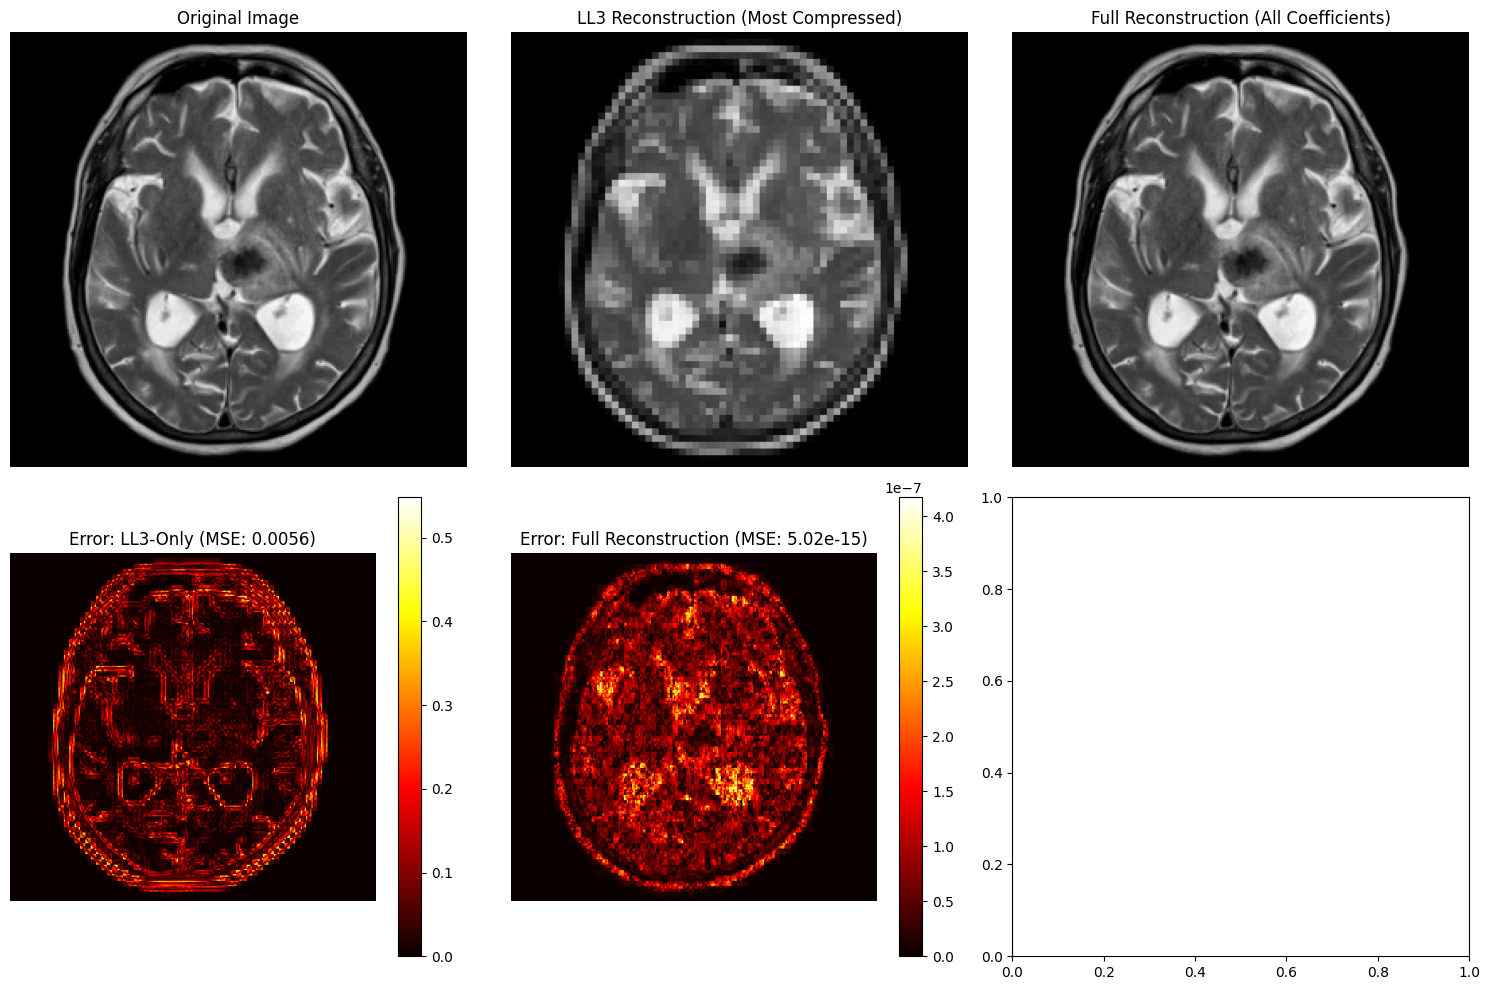

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(img_normalized, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(partial_reconstruction, cmap='gray')
axes[0, 1].set_title('LL3 Reconstruction (Most Compressed)')
axes[0, 1].axis('off')

axes[0, 2].imshow(reconstructed_full, cmap='gray')
axes[0, 2].set_title('Full Reconstruction (All Coefficients)')
axes[0, 2].axis('off')

error_map_ll3 = np.abs(img_normalized - partial_reconstruction)
axes[1, 0].imshow(error_map_ll3, cmap='hot')
axes[1, 0].set_title(f'Error: LL3-Only (MSE: {mse_partial:.4f})')
axes[1, 0].axis('off')
plt.colorbar(axes[1, 0].images[0], ax=axes[1, 0])

error_map_full = np.abs(img_normalized - reconstructed_full)
im = axes[1, 1].imshow(error_map_full, cmap='hot')
axes[1, 1].set_title(f'Error: Full Reconstruction (MSE: {mse_full:.2e})')
axes[1, 1].axis('off')
plt.colorbar(im, ax=axes[1, 1])


plt.tight_layout()
plt.show()